# Simple Feature Exploration

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from pathlib import Path
from skimage.color import rgb2gray
from skimage.filters import window, butterworth
from scipy.stats import gaussian_kde

In [20]:
metadata_full = pd.read_csv("./sample_images/metadata.csv", index_col=0)
cols_to_keep = ["image_id", "width", "height", "file_name", "common_name", "supercategory"]
metadata = metadata_full[cols_to_keep].copy()
metadata.head()

,image_id,width,height,file_name,common_name,supercategory
0,2775952,500,375,val/02988_Animalia_Chordata_Amphibia_Anura_Hyl...,Pine Woods Tree Frog,Amphibians
1,2691604,500,281,val/03091_Animalia_Chordata_Amphibia_Caudata_P...,White-spotted Slimy Salamander,Amphibians
2,2692530,500,375,val/03081_Animalia_Chordata_Amphibia_Caudata_P...,Ensatina,Amphibians
3,2704304,500,244,val/03082_Animalia_Chordata_Amphibia_Caudata_P...,Northern Two-lined Salamander,Amphibians
4,2764140,500,333,val/02976_Animalia_Chordata_Amphibia_Anura_Dic...,Alpine Cricket Frog,Amphibians


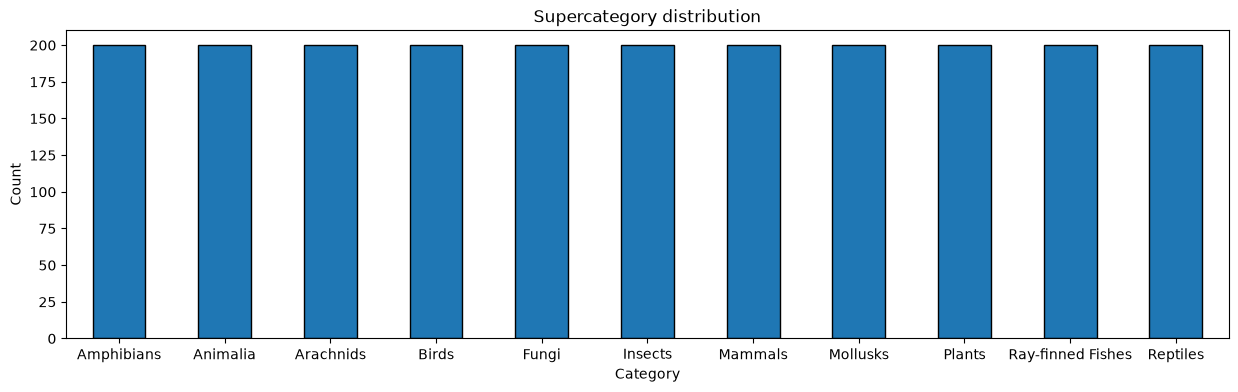

In [21]:
plt.figure(figsize=(15,4))
metadata["supercategory"].value_counts().plot(kind='bar', edgecolor='black', rot=0)
plt.title("Supercategory distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

In [22]:
sample_image_ids = metadata.groupby("supercategory")["image_id"].sample(n=1, random_state=1).tolist()
sample_df = metadata[metadata["image_id"].isin(sample_image_ids)]
sample_df

,image_id,width,height,file_name,common_name,supercategory
58,2776774,500,375,val/02992_Animalia_Chordata_Amphibia_Anura_Hyl...,Mediterranean Tree Frog,Amphibians
281,2690111,500,375,val/05207_Animalia_Echinodermata_Asteroidea_Va...,Leather Star,Animalia
465,2744209,500,466,val/00138_Animalia_Arthropoda_Arachnida_Ixodid...,Pacific Coast Tick,Arachnids
796,2748834,500,333,val/04203_Animalia_Chordata_Aves_Passeriformes...,Wrentit,Birds
816,2726931,500,406,val/05585_Fungi_Basidiomycota_Agaricomycetes_A...,shaggy pholiota,Fungi
1016,2708827,500,375,val/02061_Animalia_Arthropoda_Insecta_Lepidopt...,Mottled Emigrant,Insects
1222,2701525,500,375,val/04615_Animalia_Chordata_Mammalia_Artiodact...,Humpback Whale,Mammals
1411,2736606,500,375,val/05259_Animalia_Mollusca_Gastropoda_Archita...,Channeled Applesnail,Mollusks
1772,2748277,281,500,val/05884_Plantae_Tracheophyta_Liliopsida_Aspa...,harvest brodiaea,Plants
1826,2733628,500,408,val/02918_Animalia_Chordata_Actinopterygii_Syn...,Pot-bellied Seahorse,Ray-finned Fishes


In [23]:
data_dir = Path("./sample_images/images")
imgs = [np.array(Image.open(data_dir / path)) for path in sample_df["file_name"].tolist()]

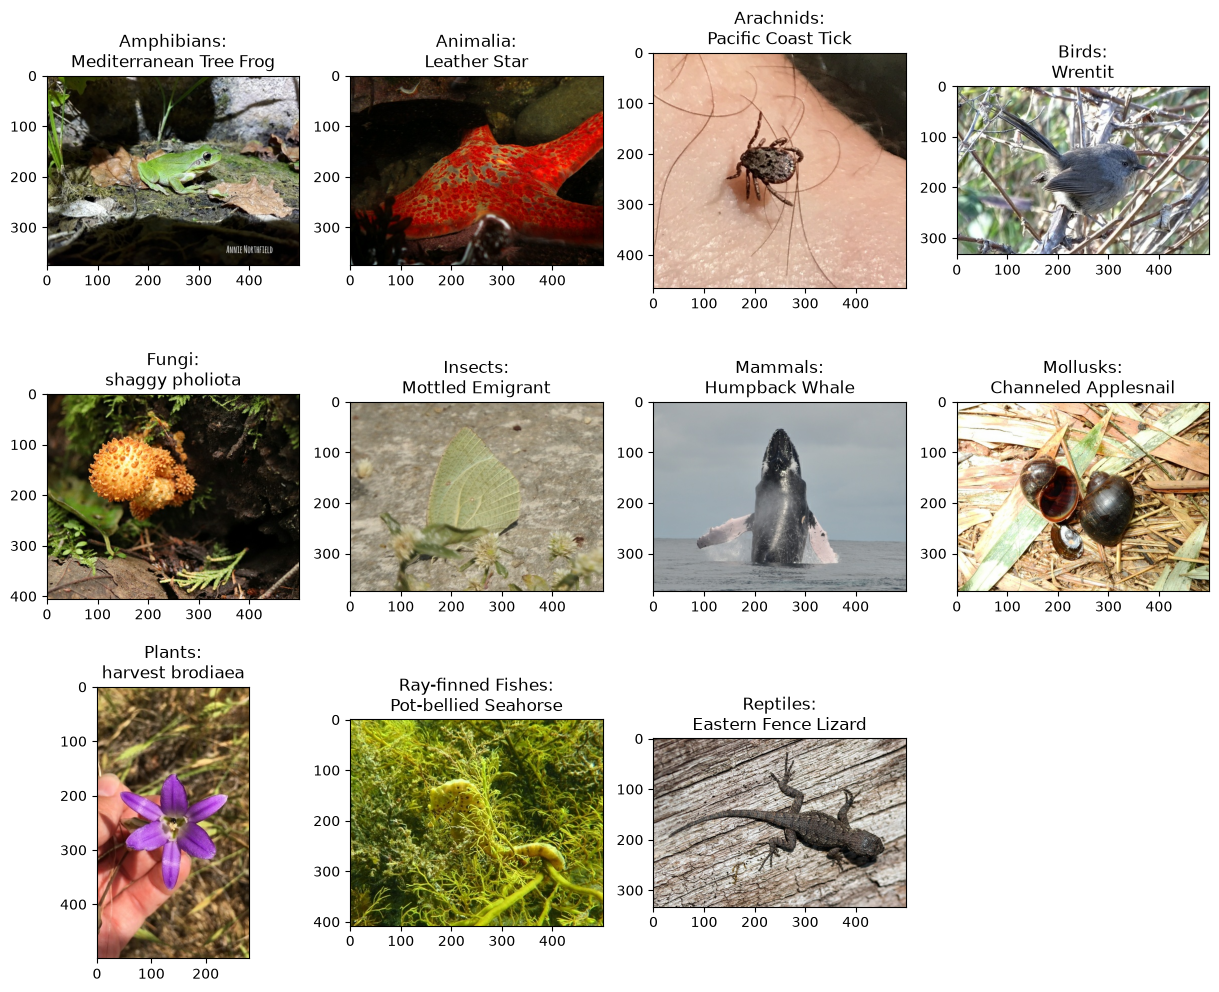

In [24]:
fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(15,12))
axes = axs.flatten()
for i in range(len(imgs)):
    axes[i].imshow(imgs[i])
    axes[i].set_title(f"{sample_df["supercategory"].tolist()[i]}:\n{sample_df["common_name"].tolist()[i]}")

axes[-1].set_visible(False)

# Color Histogram

In [25]:
def get_color_hist(img):
    colors = ('red', 'green', 'blue')
    result = {}
    for channel_id, color in enumerate(colors):
        hist, bin_edges = np.histogram(img[:, :, channel_id], bins=256, range=(0, 256))
        result[color]=hist
    result["bin_edges"]=bin_edges
    return result

In [26]:
def collect_hists(metadata, categories):
    hists_by_cat = {}
    for cat in categories:
        imgs = metadata[metadata['supercategory']==cat]["image_id"].tolist()
        color_hists = {}
        for id in imgs:
            im_path = metadata[metadata["image_id"]==id]["file_name"].tolist()[0]
            img = np.array(Image.open(data_dir / im_path))
            single_hist = get_color_hist(img)

            if color_hists:
                color_hists['red'] + single_hist['red']
                color_hists['green'] + single_hist['green']
                color_hists['blue'] + single_hist['blue']
            else:
                color_hists = single_hist
        hists_by_cat[cat]=color_hists
    return hists_by_cat

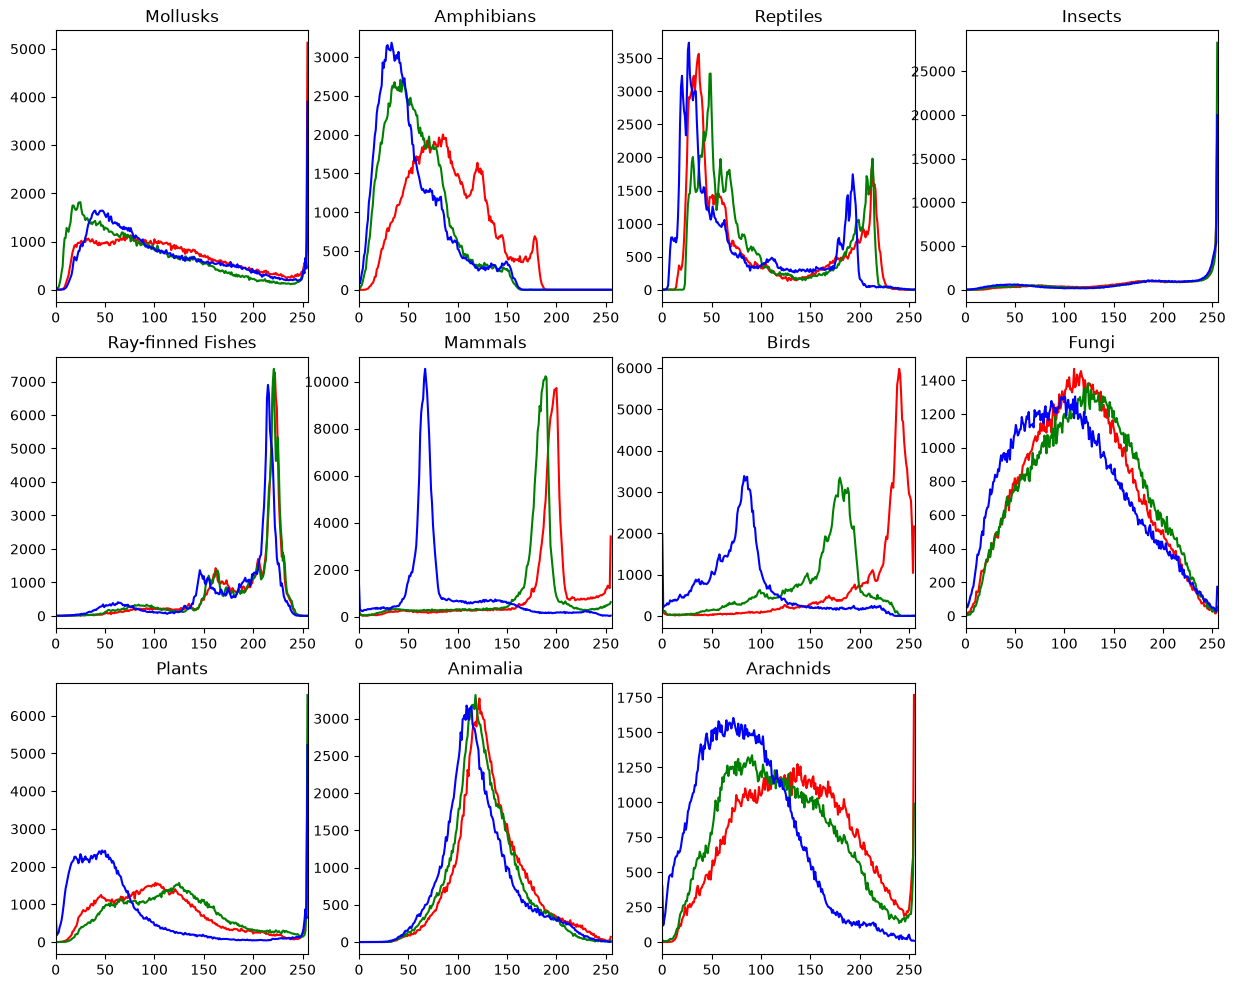

In [27]:
categories = set(metadata['supercategory'].tolist())
hists_by_cat = collect_hists(metadata, categories)

fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(15,12))
axes = axs.flatten()
for i, cat in enumerate(categories):
    bin_edges = hists_by_cat[cat]["bin_edges"]
    for color in ["red", "green", "blue"]:
        hist = hists_by_cat[cat][color]
        axes[i].plot(bin_edges[:-1], hist, color=color)
    axes[i].set_xlim([0,256])
    axes[i].set_title(cat)

axes[-1].set_visible(False)
plt.show()

# Band Pass Ratio Filter (fine vs coarse)

In [28]:
def get_BPR(img, cutoff=0.25, order=2):
    """
    Ratio of fine (high-pass) to coarse (low-pass) energy.

    cutoff : split frequency as a fraction of Nyquist (0 < cutoff <= 1).
    order  : Butterworth filter order (higher = sharper transition).
    """
    gray = rgb2gray(img)
    gray = (gray - gray.mean()) * window('hann', gray.shape)

    fc = cutoff * 0.5
    coarse = butterworth(gray, fc, high_pass=False, order=order)
    fine = butterworth(gray, fc, high_pass=True, order=order)

    return np.sum(fine ** 2) / (np.sum(coarse ** 2) + 1e-12)

In [29]:
def collect_BPR(metadata, categories):
    ratios_by_cat = {}
    for cat in categories:
        imgs = metadata[metadata['supercategory']==cat]["image_id"].tolist()
        img_ratios = []
        for id in imgs:
            im_path = metadata[metadata["image_id"]==id]["file_name"].tolist()[0]
            img = np.array(Image.open(data_dir / im_path))
            bpr = get_BPR(img)

            img_ratios.append(bpr)
        ratios_by_cat[cat]=img_ratios
    return ratios_by_cat

In [30]:
categories = set(metadata['supercategory'].tolist())
ratios_by_cat = collect_BPR(metadata, categories)

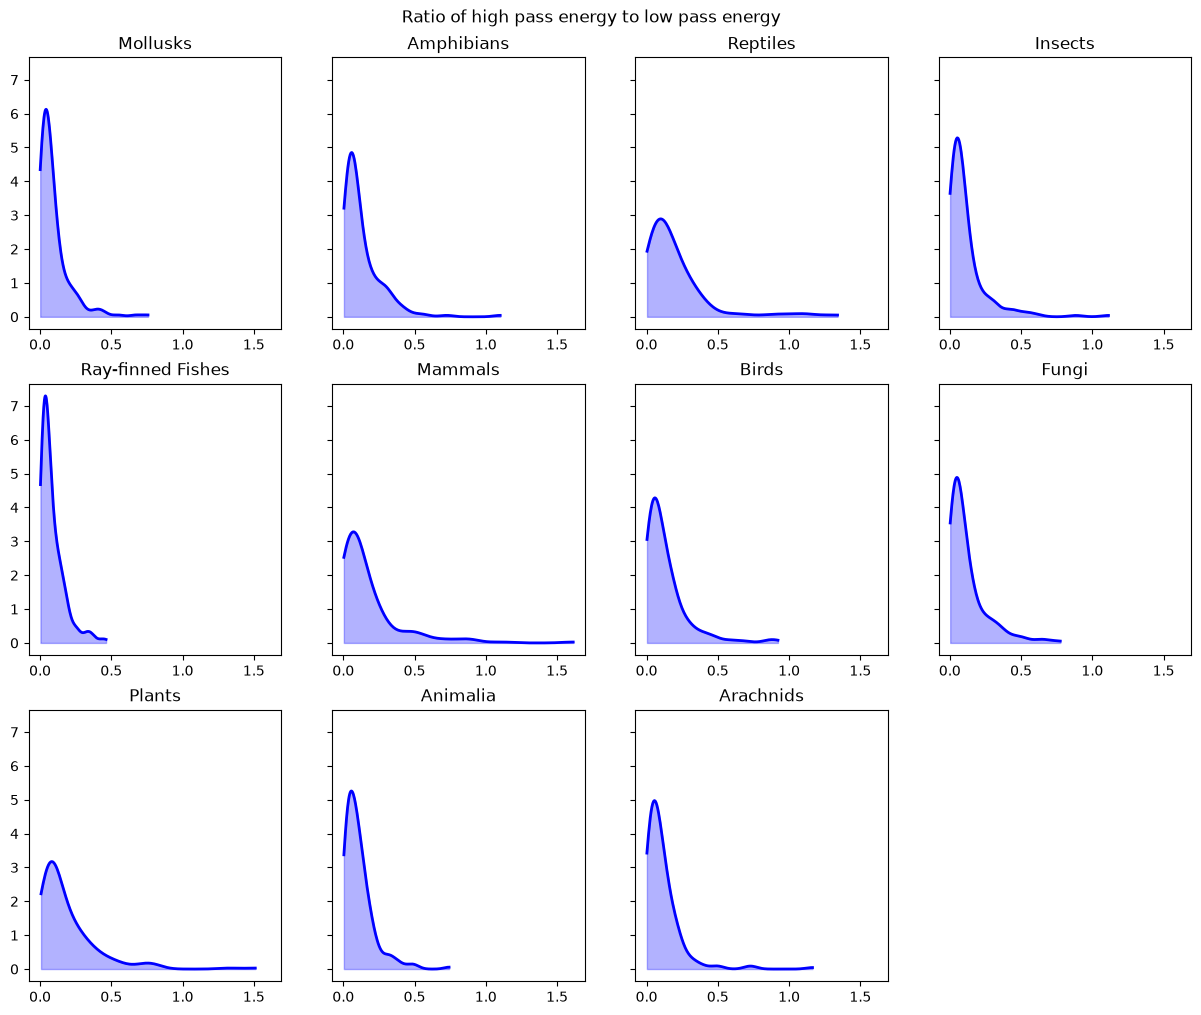

In [31]:
fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(15,12), sharex=True, sharey=True)
axes = axs.flatten()
for i, cat in enumerate(categories):
    data = ratios_by_cat[cat]
    kde = gaussian_kde(data)
    x_vals = np.linspace(min(data), max(data), 200)
    y_vals = kde(x_vals)

    axes[i].plot(x_vals, y_vals, color='blue', linewidth=2)
    axes[i].fill_between(x_vals, y_vals, color='blue', alpha=0.3)

    axes[i].set_title(cat)
    axes[i].tick_params(axis='x', labelbottom=True)

axes[-1].set_visible(False)
plt.suptitle("Ratio of high pass energy to low pass energy", y=0.92)
plt.show()